# 08. PSI: известные фазовые сдвиги

Курс «От интерференции до измерения поверхности». [Маршрут](README.md).

**Цели:** вывести четырёхкадровую формулу и общий линейный МНК по серии изображений.

Работайте сверху вниз, затем меняйте параметры и выполняйте **Restart Kernel → Run All**.
Все численные примеры учебные: они объясняют метод, а не подтверждают точность прибора.
Рекомендуемый темп: одна тетрадь за занятие, с собственными записями и упражнениями.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage, signal, interpolate, optimize

course_dir = next(p for p in [Path.cwd(), Path.cwd()/"notes"/"interferometry-course"]
                  if (p/"course_lib.py").exists())
if str(course_dir) not in sys.path:
    sys.path.insert(0, str(course_dir))
import course_lib as cl
np.set_printoptions(precision=5, suppress=True)

## 1. Что меняется между кадрами

Снимаем одну и ту же точку поверхности при известных сдвигах опорной фазы:
$$I_n(x,y)=a(x,y)+b(x,y)\cos[\varphi(x,y)+\delta_n].$$
Для каждого пикселя неизвестны a,b,φ. Между кадрами они должны оставаться достаточно
стабильными; меняется δ. Нужны регистрация кадров, линейность камеры и отсутствие
существенных изменений спекл-поля. «Больше кадров» не исправляет нарушение этой модели.

В отличие от пространственной несущей, PSI использует временное разнообразие.
Поэтому φ можно оценивать в каждом пикселе без необходимости иметь несколько полос
вдоль каждой строки. Развёртка пространственного поля остаётся отдельной задачей.

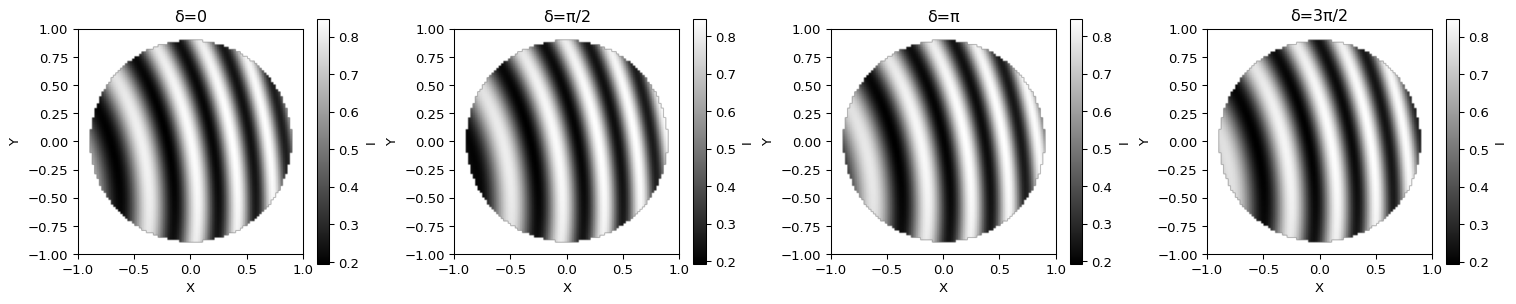

In [2]:
s=cl.scene(n=96,carrier_x=5,carrier_y=1,bowl=.5)
shifts=np.array([0,np.pi/2,np.pi,3*np.pi/2])
stack=np.array([s['a']+s['b']*np.cos(s['phi']+d) for d in shifts])
cl.show_maps(list(stack),['δ=0','δ=π/2','δ=π','δ=3π/2'],s['mask'],cmap='gray',units='I')

## 2. Четыре кадра — вывод без запоминания знака

Для принятого знака **cos(φ+δ)**:
$$I_0=a+b\cos\varphi,\ I_1=a-b\sin\varphi,\
I_2=a-b\cos\varphi,\ I_3=a+b\sin\varphi.$$
Отсюда $I_0-I_2=2b\cos\varphi$, $I_3-I_1=2b\sin\varphi$ и
$$\widehat\varphi=\operatorname{atan2}(I_3-I_1,I_0-I_2).$$
Если в литературе используется cos(φ−δ), знак числителя меняется. Проверяйте модель,
а не копируйте формулу с чужим соглашением.

In [3]:
phi4=np.arctan2(stack[3]-stack[1],stack[0]-stack[2])
phase_error=cl.wrap(phi4-s['phi'])
print('Максимальная ошибка четырёхкадровой формулы, rad:',np.max(np.abs(phase_error[s['mask']])))
assert np.max(np.abs(phase_error[s['mask']]))<1e-12

Максимальная ошибка четырёхкадровой формулы, rad: 1.2864981197413093e-15


## 3. Произвольные известные сдвиги — линейная задача

Раскрываем косинус суммы и вводим $c=b\cos\varphi$, $s=b\sin\varphi$:
$$I_n=a+c\cos\delta_n-s\sin\delta_n.$$
Матрица D имеет строки $[1,\cos\delta_n,-\sin\delta_n]$.
Сначала решаем линейный МНК по a,c,s, затем
$b=\sqrt{c^2+s^2}$, $\varphi=\operatorname{atan2}(s,c)$.

Фон и амплитуда могут различаться между пикселями: в этой постановке они
не усредняются по всему изображению. Матрица D общая для всех пикселей, поэтому
множество правых частей удобно решать одновременно. Нужен ранг 3, а не просто M≥3.

rank D: 3 κ(D): 1.613519434054952 {'rms': 0.002018975656703233, 'pv': 0.014355429984223123, 'bias': -0.9999807806945173, 'coverage': 1.0}


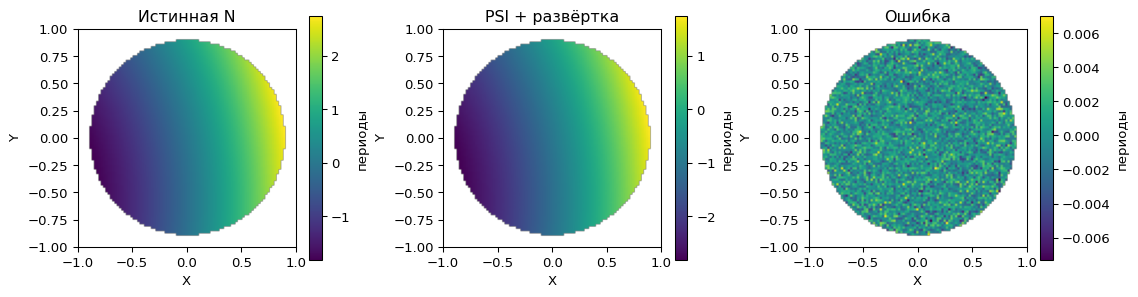

In [4]:
shifts_irregular=np.deg2rad([0,68,155,247,334])
stack=np.array([s['a']+s['b']*np.cos(s['phi']+d) for d in shifts_irregular])
noisy=np.array([cl.camera(frame,photons=15000,seed=20+i) for i,frame in enumerate(stack)])
D=np.column_stack([np.ones(len(shifts_irregular)),np.cos(shifts_irregular),-np.sin(shifts_irregular)])
coefficients,_,rank,singular=np.linalg.lstsq(D,noisy[:,s['mask']],rcond=None)
a_hat,c_hat,s_hat=coefficients
wrapped=np.full(s['mask'].shape,np.nan)
wrapped[s['mask']]=np.arctan2(s_hat,c_hat)
result=cl.psi_known(noisy,shifts_irregular,s['mask'])
assert np.allclose(wrapped[s['mask']],result['phi'][s['mask']])
unwrapped,labels=cl.unwrap_quality(wrapped,np.where(s['mask'],1,0),s['mask'])
error,stats=cl.compare(unwrapped/cl.TAU,s['orders'],s['mask'])
print('rank D:',rank,'κ(D):',singular[0]/singular[-1],stats)
cl.show_maps([s['orders'],unwrapped/cl.TAU,error],['Истинная N','PSI + развёртка','Ошибка'],s['mask'],units='периоды')

## 4. Почему важны распределение сдвигов и модуляция

Если все δ одинаковы, строки D одинаковы. Если сдвиги почти одинаковы, задача
плохо обусловлена: небольшой шум вызывает большую ошибку. Равномерное покрытие
окружности обычно даёт хорошую геометрию столбцов.

При равномерных сдвигах и независимом шуме интенсивности с дисперсией σ²
$\mathrm{Var}(c)\approx\mathrm{Var}(s)\approx2\sigma^2/M$.
Из дифференциала $d\varphi=(c\,ds-s\,dc)/b^2$:
$$\sigma_\varphi\approx\sqrt{2/M}\,\sigma/b.$$
Это локальная оценка при достаточно хорошем сигнале; при b→0 фаза становится
неопределённой, а линейное приближение перестаёт работать. Фотонный шум
гетероскедастичен: для строгой оценки нужны веса и фактическая модель камеры.

In [5]:
for degrees in [[0,90,180,270],[0,1,2,3],[0,0,180,180]]:
    d=np.deg2rad(degrees)
    matrix=np.column_stack([np.ones(len(d)),np.cos(d),-np.sin(d)])
    print(degrees,'rank=',np.linalg.matrix_rank(matrix),'κ=',np.linalg.cond(matrix))
rng=np.random.default_rng(31)
Mframes=8; b=.3; sigma=.01; true_phi=.8
d=np.arange(Mframes)*2*np.pi/Mframes
data=.5+b*np.cos(true_phi+d)[:,None]+rng.normal(0,sigma,(Mframes,1500))
matrix=np.column_stack([np.ones(Mframes),np.cos(d),-np.sin(d)])
c=np.linalg.lstsq(matrix,data,rcond=None)[0]
observed=np.std(cl.wrap(np.arctan2(c[2],c[1])-true_phi))
predicted=np.sqrt(2/Mframes)*sigma/b
print('Наблюдаемая / линейная оценка σφ:',observed,predicted)

[0, 90, 180, 270] rank= 3 κ= 1.4142135623730951
[0, 1, 2, 3] rank= 3 κ= 13129.559052554852
[0, 0, 180, 180] rank= 2 κ= inf
Наблюдаемая / линейная оценка σφ: 0.016608857536283335 0.016666666666666666


## Задания

1. Выведите формулу для трёх сдвигов 0, 2π/3, 4π/3 через общий D.
2. Замените фазу фоновой картинкой с наклоном яркости; мешает ли это известным сдвигам?
3. Сгенерируйте кадры со сдвигами 0,80,190,265°, а обработайте как 0,90,180,270°.
4. Почему `atan2(0,0)` не является измеренной нулевой фазой?

<details><summary>Разбор</summary>

Решите независимые c,s из столбцов sin/cos; при равномерных шагах столбцы
ортогональны. Пространственный фон допускается, если он стабилен между кадрами.
Неверные δ систематически смешивают c и s и создают фазовую рябь.
При b=0 угол не определён; численный возврат 0 не создаёт физической информации.
</details>

**В проекте:** `psi/PhaseShifting.cpp`, `computePhase`, `ShiftModel`, `CosineFit`.
Сопоставьте D с накоплением нормальных уравнений; объясните, почему здесь выбран
`lstsq`, а в C++ обращается маленькая 3×3 матрица.
Далее: [неизвестные сдвиги и наклоны](09_psi_unknown_and_tilt.ipynb).